In [1]:
import csv
import json
import platform
from collections import Counter, defaultdict
from decimal import Decimal, ROUND_CEILING
from itertools import combinations
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from tqdm.auto import tqdm


DATA_PATH = Path("baskets.csv")
ENCODING = "cp1251"
MIN_SUPPORT = 0.001
MIN_CONFIDENCE = 0.80
SORT_BY = "support"  # support | lexicographic
MAX_ITEMS = 7
CONFIDENCES = [0.70, 0.75, 0.80, 0.85, 0.90, 0.95]
REPEATS = 5
OUTPUT_DIR = Path("results")

OUTPUT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11})

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def load_baskets(path, encoding="cp1251"):
    with open(path, encoding=encoding, newline="") as file:
        return [
            frozenset(item.strip() for item in row if item.strip())
            for row in csv.reader(file) if any(item.strip() for item in row)
        ]


def apriori(baskets, min_support=0.01, sort_by="support"):
    if not 0 < min_support <= 1:
        raise ValueError("min_support must be in (0, 1]")
    if sort_by not in {"support", "lexicographic"}:
        raise ValueError("sort_by must be support or lexicographic")
    if not baskets:
        return []

    size = len(baskets)
    min_count = int((Decimal(str(min_support)) * size).to_integral_value(
        rounding=ROUND_CEILING
    ))
    tids = defaultdict(set)
    for index, basket in enumerate(baskets):
        for item in basket:
            tids[(item,)].add(index)

    level = {items: ids for items, ids in tids.items()
             if len(ids) >= min_count}
    result = []
    while level:
        result.extend((items, len(ids), len(ids) / size)
                      for items, ids in level.items())
        groups = defaultdict(list)
        for items in sorted(level):
            groups[items[:-1]].append(items)

        next_level = {}
        for group in groups.values():
            for left, right in combinations(group, 2):
                candidate = left + (right[-1],)
                # Apriori subset pruning
                if not all(part in level for part in
                           combinations(candidate, len(candidate) - 1)):
                    continue
                ids = level[left] & level[right]
                if len(ids) >= min_count:
                    next_level[candidate] = ids
        level = next_level

    if sort_by == "support":
        return sorted(result, key=lambda row: (-row[1], row[0]))
    return sorted(result, key=lambda row: row[0])


def association_rules(patterns, min_confidence=0.8, sort_by="support",
                      max_items=None):
    if not 0 < min_confidence <= 1:
        raise ValueError("min_confidence must be in (0, 1]")
    if sort_by not in {"support", "lexicographic"}:
        raise ValueError("sort_by must be support or lexicographic")

    counts = {items: count for items, count, _ in patterns}
    fractions = {items: share for items, _, share in patterns}
    rules = []
    for items, count, share in patterns:
        if len(items) < 2 or (max_items and len(items) > max_items):
            continue
        for size in range(1, len(items)):
            for antecedent in combinations(items, size):
                confidence = count / counts[antecedent]
                if confidence < min_confidence:
                    continue
                consequent = tuple(i for i in items if i not in antecedent)
                lift = confidence / fractions[consequent]
                rules.append((antecedent, consequent, count, share,
                              confidence, lift))

    if sort_by == "support":
        return sorted(rules, key=lambda row: (-row[2], -row[4], row[0], row[1]))
    return sorted(rules, key=lambda row: (row[0], row[1]))


def rules_table(rules):
    return pd.DataFrame({
        "rule": [", ".join(a) + " \u2192 " + ", ".join(c)
                 for a, c, *_ in rules],
        "size": [len(a) + len(c) for a, c, *_ in rules],
        "count": [row[2] for row in rules],
        "support_pct": [row[3] * 100 for row in rules],
        "confidence_pct": [row[4] * 100 for row in rules],
        "lift": [row[5] for row in rules],
    })

In [3]:
baskets = load_baskets(DATA_PATH, ENCODING)
stats = {
    "baskets": len(baskets),
    "items": len(set().union(*baskets)),
    "mean_size": sum(map(len, baskets)) / len(baskets),
    "max_size": max(map(len, baskets)),
    "python": platform.python_version(),
    "platform": platform.platform(),
    "processor": platform.processor(),
}
display(pd.Series(stats))

patterns = apriori(baskets, MIN_SUPPORT, SORT_BY)
rules = association_rules(patterns, MIN_CONFIDENCE, SORT_BY)
table = rules_table(rules)
table.to_csv(OUTPUT_DIR / "rules_selected.csv", index=False,
             encoding="utf-8-sig")
print(f"itemsets: {len(patterns)}, rules: {len(rules)}")
display(table.head(20).round(2))

baskets                                             7501
items                                                115
mean_size                                       3.909345
max_size                                              20
python                                            3.12.3
platform     Linux-6.18.44-fc-v185-x86_64-with-glibc2.39
processor                                         x86_64
dtype: object

itemsets: 6938, rules: 80


,rule,size,count,support_pct,confidence_pct,lift
0,"блинчики, говяжий фарш, рис → минеральная вода",4,16,0.21,84.21,3.53
1,"замороженные овощи, оливковое масло, помидоры ...",4,16,0.21,84.21,4.48
2,"молоко, помидоры, рис → макароны",4,16,0.21,80.00,4.26
3,"замороженные овощи, креветки, макароны, шокола...",5,15,0.20,88.24,3.70
4,"говяжий фарш, замороженные овощи, креветки, ми...",5,14,0.19,93.33,4.97
5,"красное вино, суп → минеральная вода",3,14,0.19,93.33,3.92
6,"замороженные овощи, креветки, оливковое масло ...",4,14,0.19,82.35,3.45
7,"бекон, блинчики → макароны",3,13,0.17,81.25,4.32
8,"замороженные овощи, оливковое масло, суп → мин...",4,13,0.17,81.25,3.41
9,"говяжий фарш, обезжиренное молоко → минеральна...",3,12,0.16,85.71,3.60


In [4]:
runs = []
rule_counts = {}
for confidence in tqdm(CONFIDENCES, desc="confidence"):
    rules_ = association_rules(patterns, confidence, SORT_BY)  # Untimed warm-up
    for repeat in range(REPEATS):
        start = perf_counter()
        found = apriori(baskets, MIN_SUPPORT, SORT_BY)
        middle = perf_counter()
        rules_ = association_rules(found, confidence, SORT_BY)
        end = perf_counter()
        runs.append({"confidence_pct": confidence * 100, "run": repeat + 1,
                     "apriori_s": middle - start, "rules_s": end - middle,
                     "total_s": end - start})
    rule_counts[confidence * 100] = len(rules_)
    rules_table(rules_).to_csv(
        OUTPUT_DIR / f"rules_{confidence * 100:g}pct.csv",
        index=False, encoding="utf-8-sig",
    )

runs = pd.DataFrame(runs)
summary = runs.groupby("confidence_pct")[["apriori_s", "rules_s", "total_s"]].median()
summary["rules"] = pd.Series(rule_counts)
runs.to_csv(OUTPUT_DIR / "rules_timings.csv", index=False)
summary.to_csv(OUTPUT_DIR / "rules_summary.csv")
display(summary)

confidence:   0%|          | 0/6 [00:00<?, ?it/s]

confidence:  17%|█▋        | 1/6 [00:00<00:04,  1.14it/s]

confidence:  33%|███▎      | 2/6 [00:01<00:03,  1.14it/s]

confidence:  50%|█████     | 3/6 [00:02<00:02,  1.14it/s]

confidence:  67%|██████▋   | 4/6 [00:03<00:01,  1.13it/s]

confidence:  83%|████████▎ | 5/6 [00:04<00:00,  1.12it/s]

confidence: 100%|██████████| 6/6 [00:05<00:00,  1.17it/s]

confidence: 100%|██████████| 6/6 [00:05<00:00,  1.15it/s]

,apriori_s,rules_s,total_s,rules
confidence_pct,,,,
70.0,0.147505,0.010825,0.160336,209
75.0,0.150296,0.011094,0.161390,116
80.0,0.147781,0.011167,0.158438,80
85.0,0.143354,0.010223,0.153421,28
90.0,0.151121,0.010671,0.161792,10
95.0,0.141467,0.011190,0.152054,5


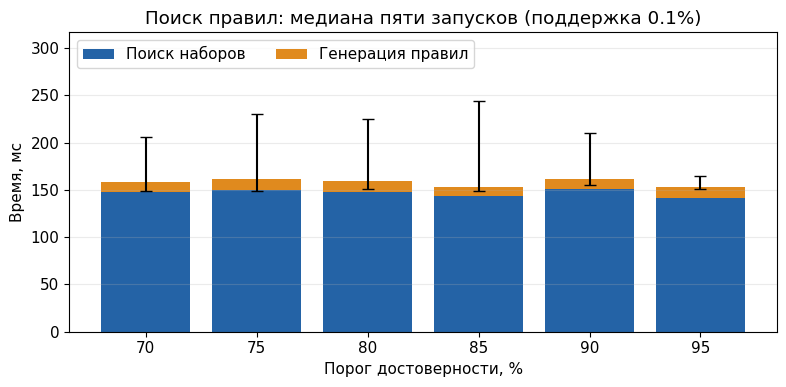

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(summary))
ax.bar(x, summary["apriori_s"] * 1000, color="#2463a6", label="Поиск наборов")
ax.bar(x, summary["rules_s"] * 1000, bottom=summary["apriori_s"] * 1000,
       color="#e08a1e", label="Генерация правил")
ax.errorbar(x, summary["total_s"] * 1000,
            yerr=[(summary["total_s"] - runs.groupby("confidence_pct")["total_s"].min()) * 1000,
                  (runs.groupby("confidence_pct")["total_s"].max() - summary["total_s"]) * 1000],
            fmt="none", ecolor="black", capsize=4)
ax.set(xlabel="Порог достоверности, %", ylabel="Время, мс",
       title=f"Поиск правил: медиана пяти запусков (поддержка {MIN_SUPPORT * 100:g}%)")
ax.set_xticks(list(x), [f"{value:g}" for value in summary.index])
ax.margins(y=0.3)
ax.legend(ncol=2, loc="upper left")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "rules_runtime.png", dpi=180)
plt.show()

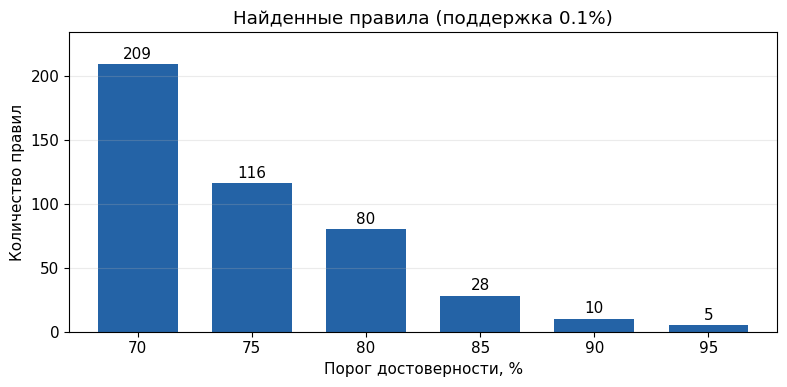

In [6]:
ax = summary["rules"].plot.bar(figsize=(8, 4), width=0.7, color="#2463a6")
ax.set(xlabel="Порог достоверности, %", ylabel="Количество правил",
       title=f"Найденные правила (поддержка {MIN_SUPPORT * 100:g}%)")
ax.set_xticklabels([f"{value:g}" for value in summary.index], rotation=0)
ax.bar_label(ax.containers[0], padding=2)
ax.grid(axis="y", alpha=0.25)
ax.margins(y=0.12)
ax.figure.tight_layout()
ax.figure.savefig(OUTPUT_DIR / "rules_count.png", dpi=180)
plt.show()

In [7]:
compact = association_rules(patterns, MIN_CONFIDENCE, SORT_BY, MAX_ITEMS)
compact_table = rules_table(compact)
compact_table.to_csv(OUTPUT_DIR / "rules_compact.csv", index=False,
                     encoding="utf-8-sig")
print(f"rules with at most {MAX_ITEMS} items: {len(compact_table)}")
display(compact_table["size"].value_counts().sort_index())
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(compact_table.round(2))

rules with at most 7 items: 80


size
3    14
4    46
5    19
6     1
Name: count, dtype: int64

,rule,size,count,support_pct,confidence_pct,lift
0,"блинчики, говяжий фарш, рис → минеральная вода",4,16,0.21,84.21,3.53
1,"замороженные овощи, оливковое масло, помидоры → макароны",4,16,0.21,84.21,4.48
2,"молоко, помидоры, рис → макароны",4,16,0.21,80.00,4.26
3,"замороженные овощи, креветки, макароны, шоколад → минеральная вода",5,15,0.20,88.24,3.70
4,"говяжий фарш, замороженные овощи, креветки, минеральная вода → макароны",5,14,0.19,93.33,4.97
5,"красное вино, суп → минеральная вода",3,14,0.19,93.33,3.92
6,"замороженные овощи, креветки, оливковое масло → минеральная вода",4,14,0.19,82.35,3.45
7,"бекон, блинчики → макароны",3,13,0.17,81.25,4.32
8,"замороженные овощи, оливковое масло, суп → минеральная вода",4,13,0.17,81.25,3.41
9,"говяжий фарш, обезжиренное молоко → минеральная вода",3,12,0.16,85.71,3.60
